# Nashville Housing — Data Cleaning and Exploration

**The question:** What drives the sale price of a home in Nashville, and how often do homes sell above their assessed value?

**The data:** 56,477 property sales × 19 columns, January 2013 to December 2016 (plus two records dated 2019 that are dropped as errors).

**Tools:** Python (pandas, NumPy, Matplotlib) and scikit-learn for a cross-validated linear model.

The notebook cleans the file step by step, explores what drives price, and checks one suspicious group of sales. The cleaned file is saved as `nashville_housing_clean.csv`.

## 1. Load and inspect

Before cleaning anything I check the shape, the data types, missing values, duplicates and a set of specific problems I expect in this file: text dates, a Yes/No column written several ways, impossible bedroom counts, homes built after their sale date, and rare land-use codes.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#E7E6E6",
    "axes.axisbelow": True,
})
plt.rcParams["text.parse_math"] = False

# Resolve paths whether the notebook is executed from the project folder or the repo root
HERE = Path.cwd()
if HERE.name == "python-cleaning-eda":
    PROJECT, ROOT = HERE, HERE.parent
else:
    PROJECT, ROOT = HERE / "python-cleaning-eda", HERE

CANDIDATES = [
    ROOT / ".rawdata" / "Nashville_Housing_Data.csv",
    PROJECT / "data" / "Nashville_Housing_Data.csv",
]
RAW = next(p for p in CANDIDATES if p.exists())
print("Reading:", RAW)

df = pd.read_csv(RAW, encoding="cp1252")
print("Shape:", df.shape)
df.head()

Reading: /home/user/data-analyst-portfolio/.rawdata/Nashville_Housing_Data.csv
Shape: (56477, 19)


,UniqueID,ParcelID,LandUse,PropertyAddress,SaleDate,SalePrice,LegalReference,SoldAsVacant,OwnerName,OwnerAddress,Acreage,TaxDistrict,LandValue,BuildingValue,TotalValue,YearBuilt,Bedrooms,FullBath,HalfBath
0,2045,007 00 0 125.00,SINGLE FAMILY,"1808 FOX CHASE DR, GOODLETTSVILLE","April 9, 2013",240000,20130412-0036474,No,"FRAZIER, CYRENTHA LYNETTE","1808 FOX CHASE DR, GOODLETTSVILLE, TN",2.3,GENERAL SERVICES DISTRICT,50000.0,168200.0,235700.0,1986.0,3.0,3.0,0.0
1,16918,007 00 0 130.00,SINGLE FAMILY,"1832 FOX CHASE DR, GOODLETTSVILLE","June 10, 2014",366000,20140619-0053768,No,"BONER, CHARLES & LESLIE","1832 FOX CHASE DR, GOODLETTSVILLE, TN",3.5,GENERAL SERVICES DISTRICT,50000.0,264100.0,319000.0,1998.0,3.0,3.0,2.0
2,54582,007 00 0 138.00,SINGLE FAMILY,"1864 FOX CHASE DR, GOODLETTSVILLE","September 26, 2016",435000,20160927-0101718,No,"WILSON, JAMES E. & JOANNE","1864 FOX CHASE DR, GOODLETTSVILLE, TN",2.9,GENERAL SERVICES DISTRICT,50000.0,216200.0,298000.0,1987.0,4.0,3.0,0.0
3,43070,007 00 0 143.00,SINGLE FAMILY,"1853 FOX CHASE DR, GOODLETTSVILLE","January 29, 2016",255000,20160129-0008913,No,"BAKER, JAY K. & SUSAN E.","1853 FOX CHASE DR, GOODLETTSVILLE, TN",2.6,GENERAL SERVICES DISTRICT,50000.0,147300.0,197300.0,1985.0,3.0,3.0,0.0
4,22714,007 00 0 149.00,SINGLE FAMILY,"1829 FOX CHASE DR, GOODLETTSVILLE","October 10, 2014",278000,20141015-0095255,No,"POST, CHRISTOPHER M. & SAMANTHA C.","1829 FOX CHASE DR, GOODLETTSVILLE, TN",2.0,GENERAL SERVICES DISTRICT,50000.0,152300.0,202300.0,1984.0,4.0,3.0,0.0


In [2]:
print("Columns and types")
print("-" * 60)
print(df.dtypes.to_string())

print("\nMissing values")
print("-" * 60)
print(df.isna().sum().to_string())

print("\nDuplicate checks")
print("-" * 60)
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate parcel + sale date:", df.duplicated(subset=["ParcelID", "SaleDate"]).sum())
print("Duplicate parcel + date + price + value:",
      df.duplicated(subset=["ParcelID", "SaleDate", "SalePrice", "TotalValue"]).sum())

print("\nSpecific problems")
print("-" * 60)
print("SoldAsVacant values:", df["SoldAsVacant"].value_counts(dropna=False).to_dict())
print("LandUse categories:", df["LandUse"].nunique())
print("Homes with 0 bedrooms:", (pd.to_numeric(df["Bedrooms"], errors="coerce") == 0).sum())

sale_year = pd.to_datetime(df["SaleDate"], format="%B %d, %Y", errors="coerce").dt.year
year_built = pd.to_numeric(df["YearBuilt"], errors="coerce")
print("Homes built after their sale date:", (year_built > sale_year).sum())
print("Sale years:", sale_year.value_counts().sort_index().to_dict())

Columns and types
------------------------------------------------------------
UniqueID             int64
ParcelID               str
LandUse                str
PropertyAddress        str
SaleDate               str
SalePrice              str
LegalReference         str
SoldAsVacant           str
OwnerName              str
OwnerAddress           str
Acreage            float64
TaxDistrict            str
LandValue          float64
BuildingValue      float64
TotalValue         float64
YearBuilt          float64
Bedrooms           float64
FullBath           float64
HalfBath           float64

Missing values
------------------------------------------------------------


UniqueID               0
ParcelID               0
LandUse                0
PropertyAddress       29
SaleDate               0
SalePrice              0
LegalReference         0
SoldAsVacant           0
OwnerName          31216
OwnerAddress       30462
Acreage            30462
TaxDistrict        30462
LandValue          30462
BuildingValue      30462
TotalValue         30462
YearBuilt          32314
Bedrooms           32320
FullBath           32202
HalfBath           32333

Duplicate checks
------------------------------------------------------------
Exact duplicate rows: 0
Duplicate parcel + sale date: 347
Duplicate parcel + date + price + value: 168

Specific problems
------------------------------------------------------------
SoldAsVacant values: {'No': 51403, 'Yes': 4623, 'N': 399, 'Y': 52}
LandUse categories: 39
Homes with 0 bedrooms: 43
Homes built after their sale date: 783
Sale years: {2013: 11292, 2014: 14283, 2015: 16829, 2016: 14071, 2019: 2}


## 2. Clean

Every step is logged with the row count after it, so the effect of each decision is visible. The order matters: I remove duplicate sales first, then fix types, then filter to the rows that can actually answer the question.

| Step | What it does |
|---|---|
| Drop duplicate sales | Same parcel, date, price and assessed value (168 rows) |
| Parse dates and prices | Text → real dates and numbers |
| Normalise `SoldAsVacant` | `Y`/`N` → `Yes`/`No` |
| Numeric conversions | Acreage, land/building/total value, year built, bedrooms, baths |
| Impossible bedrooms | 0 bedrooms → missing |
| Keep rows with bedrooms and an assessed value | Needed for the price and over/under analysis |
| Split the address | Street and city, with repeated spaces collapsed |
| Flag homes built after sale | `BuiltAfterSale` |
| Group rare land use | Codes with fewer than 100 sales → `OTHER` |
| Add price features | Over/under assessment, sale-to-value ratio, price per acre |

In [3]:
log = []

def step(label, frame):
    log.append({"step": label, "rows": len(frame)})
    print(f"{label:<48} {len(frame):>8,} rows")

raw = df.copy()
step("Raw file", raw)

clean = raw.drop_duplicates(subset=["ParcelID", "SaleDate", "SalePrice", "TotalValue"]).copy()
step("Drop duplicate sales", clean)

clean["SaleDate"] = pd.to_datetime(clean["SaleDate"], format="%B %d, %Y", errors="coerce")
clean["SalePrice"] = pd.to_numeric(
    clean["SalePrice"].astype(str).str.replace(r"[\$,]", "", regex=True), errors="coerce"
)
clean = clean[clean["SalePrice"].notna() & (clean["SalePrice"] > 0)]
step("Keep valid sale prices", clean)

clean = clean[clean["SaleDate"].notna()]
clean = clean[clean["SaleDate"].dt.year < 2019]
step("Keep valid dates (drops 2 rows dated 2019)", clean)

clean["SoldAsVacant"] = (
    clean["SoldAsVacant"].astype(str).str.strip().str.upper()
    .map({"Y": "Yes", "N": "No", "YES": "Yes", "NO": "No"})
)
for col in ["Acreage", "LandValue", "BuildingValue", "TotalValue",
            "YearBuilt", "Bedrooms", "FullBath", "HalfBath"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
clean["Bedrooms"] = clean["Bedrooms"].replace(0, np.nan)

clean = clean[clean["Bedrooms"].notna()]
step("Keep rows with a bedroom count", clean)

clean = clean[clean["TotalValue"].notna() & (clean["TotalValue"] > 0)]
step("Keep rows with an assessed value", clean)

clean["BuiltAfterSale"] = clean["YearBuilt"] > clean["SaleDate"].dt.year
clean["SaleYear"] = clean["SaleDate"].dt.year

address = clean["PropertyAddress"].astype(str)
clean["StreetAddress"] = (
    address.str.split(",").str[0].str.strip().str.replace(r"\s+", " ", regex=True)
)
clean["City"] = address.str.split(",").str[-1].str.strip()

counts = clean["LandUse"].value_counts()
clean["LandUseGroup"] = np.where(
    clean["LandUse"].isin(counts[counts >= 100].index), clean["LandUse"], "OTHER"
)

clean["OverAssessed"] = np.where(clean["SalePrice"] > clean["TotalValue"], "Over", "Under")
clean["SaleToValueRatio"] = clean["SalePrice"] / clean["TotalValue"]
clean["PricePerAcre"] = clean["SalePrice"] / clean["Acreage"]

clean = clean.reset_index(drop=True)
step("Final cleaned dataset", clean)
print("\nColumns:", clean.shape[1])

Raw file                                           56,477 rows


Drop duplicate sales                               56,309 rows
Keep valid sale prices                             56,309 rows
Keep valid dates (drops 2 rows dated 2019)         56,307 rows
Keep rows with a bedroom count                     24,043 rows
Keep rows with an assessed value                   24,043 rows


Final cleaned dataset                              24,043 rows

Columns: 27


In [4]:
pd.DataFrame(log)

,step,rows
0,Raw file,56477
1,Drop duplicate sales,56309
2,Keep valid sale prices,56309
3,Keep valid dates (drops 2 rows dated 2019),56307
4,Keep rows with a bedroom count,24043
5,Keep rows with an assessed value,24043
6,Final cleaned dataset,24043


## 3. Explore

### 3.1 Price distribution, price trend and over-assessment

The sale price is heavily right-skewed, so I look at it on a log scale and use medians rather than means. The over-assessment share is the share of sales where the sale price was higher than the assessed value.

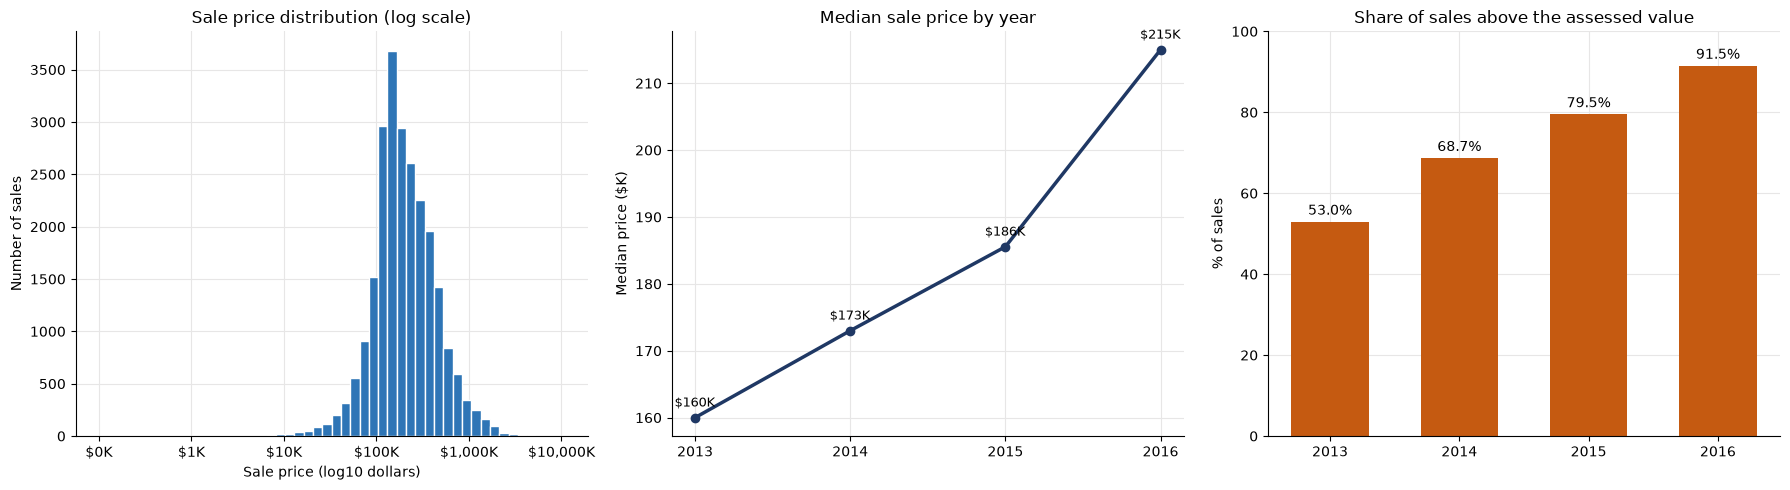

Median sale price:      $185,000
Median assessed value:  $154,500
Sales above assessment: 74.0%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Log price distribution
axes[0].hist(np.log10(clean["SalePrice"]), bins=50, color="#2E75B6", edgecolor="white")
axes[0].set_title("Sale price distribution (log scale)")
axes[0].set_xlabel("Sale price (log10 dollars)")
axes[0].set_ylabel("Number of sales")
axes[0].xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"${10**x/1000:,.0f}K")
)

# 2. Median price by year
by_year = clean.groupby("SaleYear").agg(
    median_price=("SalePrice", "median"), sales=("SalePrice", "size")
)
axes[1].plot(by_year.index, by_year["median_price"] / 1000,
             marker="o", color="#1F3864", linewidth=2.5)
axes[1].set_title("Median sale price by year")
axes[1].set_ylabel("Median price ($K)")
axes[1].set_xticks(by_year.index)
for x, y in zip(by_year.index, by_year["median_price"] / 1000):
    axes[1].annotate(f"${y:,.0f}K", (x, y), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=9)

# 3. Over-assessed share by year
over_year = clean.groupby("SaleYear")["OverAssessed"].apply(lambda s: (s == "Over").mean() * 100)
axes[2].bar(over_year.index.astype(str), over_year.values, color="#C55A11", width=0.6)
axes[2].set_title("Share of sales above the assessed value")
axes[2].set_ylabel("% of sales")
axes[2].set_ylim(0, 100)
for x, y in zip(over_year.index.astype(str), over_year.values):
    axes[2].annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                     xytext=(0, 5), ha="center", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Median sale price:      ${clean['SalePrice'].median():,.0f}")
print(f"Median assessed value:  ${clean['TotalValue'].median():,.0f}")
print(f"Sales above assessment: {(clean['OverAssessed'] == 'Over').mean():.1%}")

### 3.2 What drives the sale price?

The correlation matrix shows which features move with price. I then fit a cross-validated ridge regression on log price and add groups of features one at a time, so each step shows how much that group explains. Using log price keeps the model from being dominated by a handful of very expensive homes.

| Model | Features added | Cross-validated R² |
|---|---|---|
| 1 | Assessed value only | 0.639 |
| 2 | + city | 0.641 |
| 3 | + land use | 0.684 |
| 4 | + size, rooms, age, sale year, city and land use | 0.734 |

The assessed value alone explains about 64% of the variation in sale price. Adding the physical attributes and location raises that to 73%, so the assessment is a strong starting point but not the whole story.

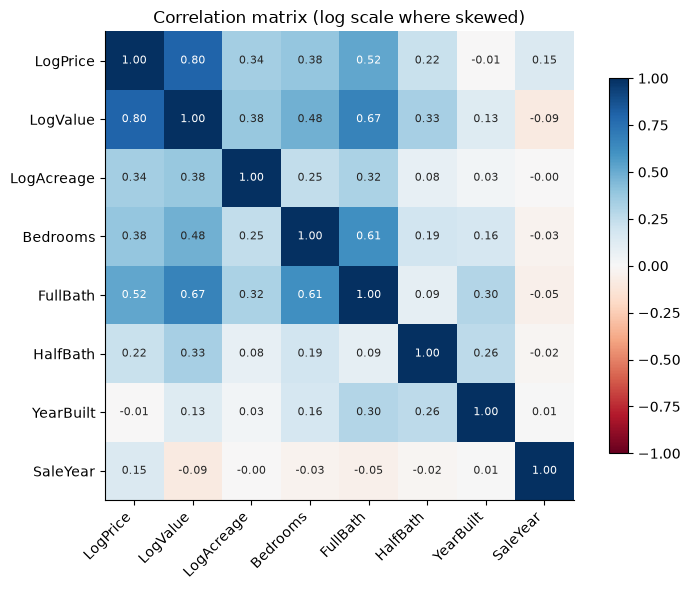

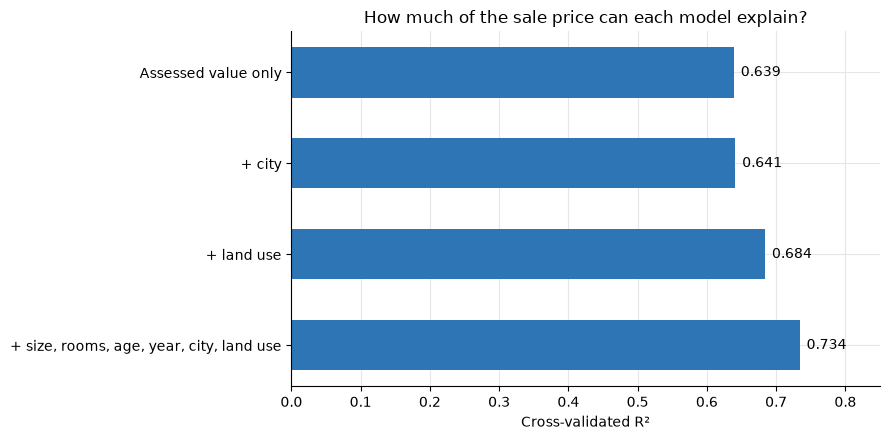

How much of the assessed value can each model explain?
               model  cv_r2     n
Size, rooms, acreage  0.551 23911
              + city  0.605 23911
   + city + land use  0.646 23911


,model,cv_r2,n
0,Assessed value only,0.639,24043
1,+ city,0.641,24043
2,+ land use,0.684,24043
3,"+ size, rooms, age, year, city, land use",0.734,23911


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold

clean["LogPrice"] = np.log(clean["SalePrice"])
clean["LogValue"] = np.log(clean["TotalValue"])
clean["LogAcreage"] = np.log1p(clean["Acreage"])

corr_vars = ["LogPrice", "LogValue", "LogAcreage", "Bedrooms",
             "FullBath", "HalfBath", "YearBuilt", "SaleYear"]
corr = clean[corr_vars].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars)), corr_vars, rotation=45, ha="right")
ax.set_yticks(range(len(corr_vars)), corr_vars)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "#262626")
ax.set_title("Correlation matrix (log scale where skewed)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()


def cv_r2(data, num_cols, cat_cols, target):
    """5-fold cross-validated R² for a ridge model."""
    d = data.dropna(subset=[target] + num_cols)
    X = d[num_cols + cat_cols]
    y = d[target]
    pre = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    model = Pipeline([("pre", pre), ("ridge", Ridge(alpha=1.0))])
    scores = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=42),
                             scoring="r2")
    return scores.mean(), len(d)


models = [
    ("Assessed value only", ["LogValue"], []),
    ("+ city", ["LogValue"], ["City"]),
    ("+ land use", ["LogValue"], ["LandUseGroup"]),
    ("+ size, rooms, age, year, city, land use",
     ["LogValue", "Bedrooms", "FullBath", "HalfBath", "LogAcreage", "YearBuilt", "SaleYear"],
     ["City", "LandUseGroup"]),
]
results = []
for name, nums, cats in models:
    r2, n = cv_r2(clean, nums, cats, "LogPrice")
    results.append({"model": name, "cv_r2": round(r2, 3), "n": n})

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(results_df["model"], results_df["cv_r2"], color="#2E75B6", height=0.55)
ax.set_xlabel("Cross-validated R²")
ax.set_title("How much of the sale price can each model explain?")
ax.set_xlim(0, 0.85)
for y, v in zip(results_df["model"], results_df["cv_r2"]):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# The same question for the assessed value itself: how much do the physical
# features explain, and how much does location add?
value_models = [
    ("Size, rooms, acreage", ["Bedrooms", "FullBath", "HalfBath", "LogAcreage"], []),
    ("+ city", ["Bedrooms", "FullBath", "HalfBath", "LogAcreage"], ["City"]),
    ("+ city + land use", ["Bedrooms", "FullBath", "HalfBath", "LogAcreage"],
     ["City", "LandUseGroup"]),
]
value_results = []
for name, nums, cats in value_models:
    r2, n = cv_r2(clean, nums, cats, "LogValue")
    value_results.append({"model": name, "cv_r2": round(r2, 3), "n": n})
value_results_df = pd.DataFrame(value_results)
print("How much of the assessed value can each model explain?")
print(value_results_df.to_string(index=False))

results_df

### 3.3 Location, land use and age

Location is the biggest visible gap. Brentwood's median sale is about $420K, against $129K in Madison and $131K in Antioch — roughly 3.3 times higher. The share of sales above assessment also varies by city, from 64% in Madison to 82% in Antioch.

Age is not a straight line: homes built before the 1930s and after 2000 sell for more than those from the 1950s to the 1980s. That is consistent with both historic homes and new construction commanding a premium.

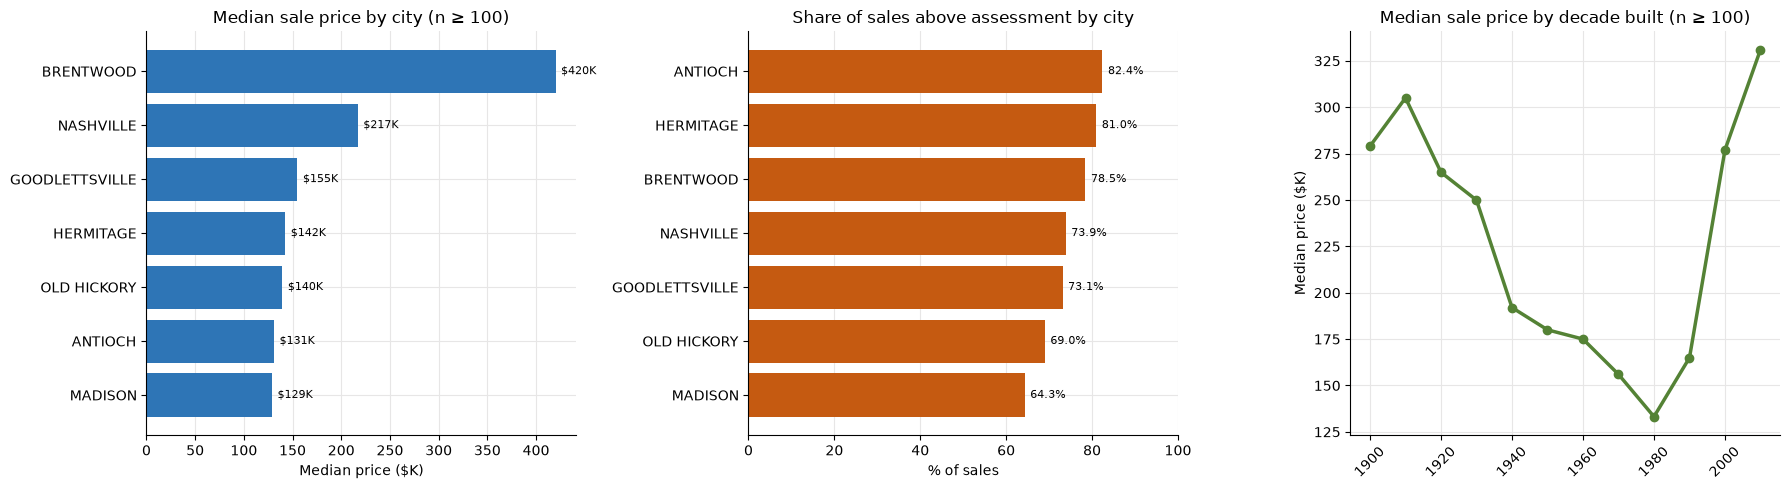

                median_price  sales
City                               
MADISON             128900.0   1213
ANTIOCH             131000.0   1274
OLD HICKORY         139500.0    858
HERMITAGE           142500.0   1025
GOODLETTSVILLE      155000.0    454
NASHVILLE           217000.0  18984
BRENTWOOD           420000.0    181

        median_price  sales
Decade                     
1900.0      279000.0    123
1910.0      305000.0    293
1920.0      264900.0   1405
1930.0      249900.0   2097
1940.0      192000.0   2562
1950.0      180000.0   5124
1960.0      175000.0   3939
1970.0      156000.0   2004
1980.0      133200.0   2414
1990.0      164945.0    926
2000.0      277000.0    793
2010.0      331000.0   2263


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

city_stats = clean.groupby("City").agg(
    median_price=("SalePrice", "median"), sales=("SalePrice", "size")
)
city_stats = city_stats[city_stats["sales"] >= 100].sort_values("median_price")

axes[0].barh(city_stats.index, city_stats["median_price"] / 1000, color="#2E75B6")
axes[0].set_title("Median sale price by city (n ≥ 100)")
axes[0].set_xlabel("Median price ($K)")
for y, v in zip(city_stats.index, city_stats["median_price"] / 1000):
    axes[0].annotate(f"${v:,.0f}K", (v, y), xytext=(4, 0),
                     textcoords="offset points", va="center", fontsize=8)

over_city = clean.groupby("City")["OverAssessed"].apply(lambda s: (s == "Over").mean() * 100)
over_city = over_city[city_stats.index].sort_values()
axes[1].barh(over_city.index, over_city.values, color="#C55A11")
axes[1].set_title("Share of sales above assessment by city")
axes[1].set_xlabel("% of sales")
axes[1].set_xlim(0, 100)
for y, v in zip(over_city.index, over_city.values):
    axes[1].annotate(f"{v:.1f}%", (v, y), xytext=(4, 0),
                     textcoords="offset points", va="center", fontsize=8)

decade = clean.assign(Decade=(clean["YearBuilt"] // 10 * 10)).groupby("Decade").agg(
    median_price=("SalePrice", "median"), sales=("SalePrice", "size")
)
decade = decade[decade["sales"] >= 100]
axes[2].plot(decade.index, decade["median_price"] / 1000,
             marker="o", color="#548235", linewidth=2.5)
axes[2].set_title("Median sale price by decade built (n ≥ 100)")
axes[2].set_ylabel("Median price ($K)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(city_stats.round(0).to_string())
print()
print(decade.round(0).to_string())

### 3.4 Check a suspicion: homes built after their sale date

768 sales have a year built *after* the sale year. That usually means the assessment includes a building that did not exist when the property was sold (for example, a pre-construction sale). These rows behave very differently: only 4.2% sell above the assessed value, against 76.3% of other sales, and their median price is $150K against $185K.

I keep them in the cleaned file with a flag but leave them out of the over/under comparison. The rising over-assessment trend is the same either way, so the conclusion does not depend on this choice.

                sales  median_price  over_share
BuiltAfterSale                                 
False           23275      185000.0        76.3
True              768      150000.0         4.2


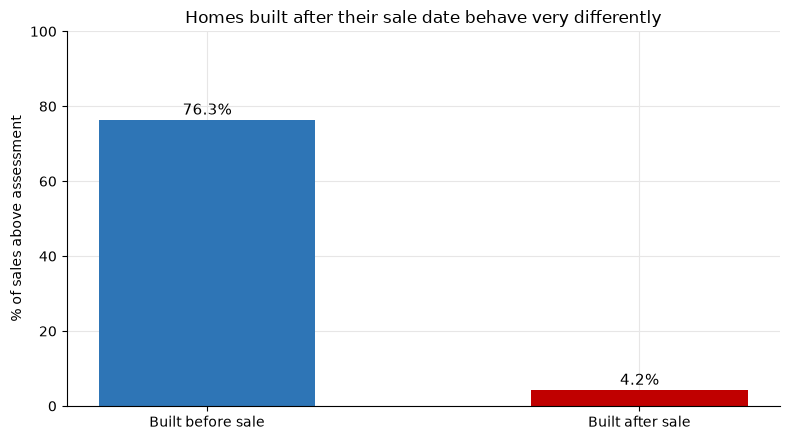

BuiltFlag  Built after sale  Other sales
SaleYear                                
2013                    3.4         55.3
2014                    3.9         71.9
2015                    4.9         82.3
2016                   20.0         91.6


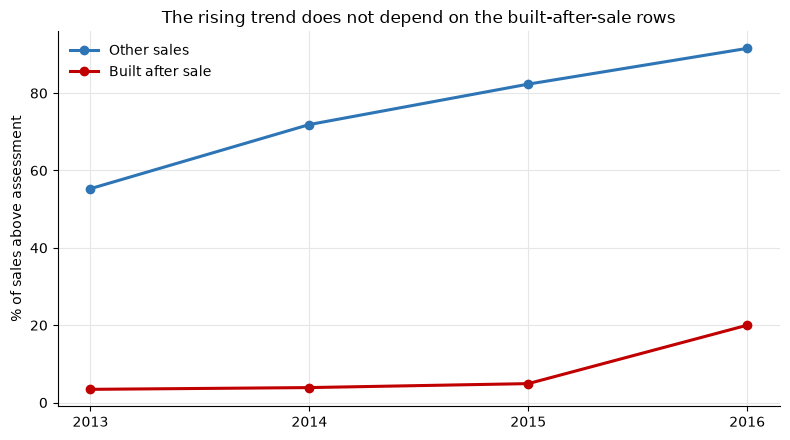

In [8]:
check = clean.groupby("BuiltAfterSale").agg(
    sales=("SalePrice", "size"),
    median_price=("SalePrice", "median"),
    over_share=("OverAssessed", lambda s: (s == "Over").mean() * 100),
)
print(check.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
values = [check.loc[False, "over_share"], check.loc[True, "over_share"]]
ax.bar(["Built before sale", "Built after sale"], values, color=["#2E75B6", "#C00000"], width=0.5)
ax.set_ylabel("% of sales above assessment")
ax.set_title("Homes built after their sale date behave very differently")
for i, v in enumerate(values):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=11)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# Does the trend depend on including them?
clean["BuiltFlag"] = clean["BuiltAfterSale"].map(
    {True: "Built after sale", False: "Other sales"}
)
trend = clean.pivot_table(
    index="SaleYear", columns="BuiltFlag", values="OverAssessed",
    aggfunc=lambda s: (s == "Over").mean() * 100,
)
print(trend.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for column, color in [("Other sales", "#2E75B6"), ("Built after sale", "#C00000")]:
    ax.plot(trend.index, trend[column], marker="o", linewidth=2.2, color=color, label=column)
ax.set_xticks(trend.index)
ax.set_ylabel("% of sales above assessment")
ax.set_title("The rising trend does not depend on the built-after-sale rows")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Key findings

- **Most homes sell above their assessed value, and the share rises every year.** 53.0% of 2013 sales were above assessment, then 68.7%, 79.5% and 91.5% in 2016. The median sale price rose from $160K to $215K over the same period.
- **The assessed value is the strongest single predictor of sale price.** On its own it explains 64% of the variation in log sale price (cross-validated R²); adding size, rooms, age, location and land use raises that to 73%.
- **Location matters more than any physical feature.** Brentwood's median sale is about $420K, against $129K in Madison and $131K in Antioch, roughly 3.3 times higher. Antioch has the highest over-assessment share (82.4%) and Madison the lowest (64.3%).
- **Size and rooms explain about 57% of the assessed value** (cross-validated R²); adding city raises it to 61% and land use to 65%.
- **Age is not linear.** Homes built before the 1930s and after 2000 sell for more than those from the 1950s to the 1980s: the 2010s median is $331K against $133K for the 1980s.
- **Homes built after their sale date are a different product.** Only 4.2% of them sell above assessment, against 76.3% of other sales, and their median price is $150K against $185K. They are flagged in the cleaned file and excluded from the over/under comparison.
- **Vacant land also behaves differently:** only 6.1% of vacant-land sales are above assessment, against 75.2% of improved properties.

## 5. What I'd do next

- Add the actual sale price and assessment date to the model; the current file has the sale price but not when the assessment was made.
- Bring in neighbourhood or map data to model location more precisely than city.
- Compare this linear model with one that can handle interactions, such as gradient boosting, and check whether the over-assessment gap is driven by specific land uses or price bands.

## 6. Export

The cleaned file keeps the 26 columns that are useful for analysis: the original fields (renamed to `snake_case`), the split address and city, the land-use group, the built-after-sale flag, and the price features.

In [9]:
export = clean.rename(columns={
    "ParcelID": "parcel_id",
    "LandUse": "land_use",
    "LandUseGroup": "land_use_group",
    "PropertyAddress": "property_address",
    "StreetAddress": "street_address",
    "City": "city",
    "SaleDate": "sale_date",
    "SaleYear": "sale_year",
    "SalePrice": "sale_price",
    "LegalReference": "legal_reference",
    "SoldAsVacant": "sold_as_vacant",
    "OwnerName": "owner_name",
    "OwnerAddress": "owner_address",
    "Acreage": "acreage",
    "TaxDistrict": "tax_district",
    "LandValue": "land_value",
    "BuildingValue": "building_value",
    "TotalValue": "total_value",
    "YearBuilt": "year_built",
    "Bedrooms": "bedrooms",
    "FullBath": "full_bath",
    "HalfBath": "half_bath",
    "BuiltAfterSale": "built_after_sale",
    "OverAssessed": "over_assessed",
    "SaleToValueRatio": "sale_to_value_ratio",
    "PricePerAcre": "price_per_acre",
})

export = export[[
    "parcel_id", "land_use", "land_use_group", "property_address", "street_address",
    "city", "sale_date", "sale_year", "sale_price", "legal_reference", "sold_as_vacant",
    "owner_name", "owner_address", "acreage", "tax_district", "land_value",
    "building_value", "total_value", "year_built", "bedrooms", "full_bath", "half_bath",
    "built_after_sale", "over_assessed", "sale_to_value_ratio", "price_per_acre",
]]
export.to_csv(PROJECT / "nashville_housing_clean.csv", index=False)
print(f"Saved {len(export):,} rows × {export.shape[1]} columns to nashville_housing_clean.csv")
export.head()

Saved 24,043 rows × 26 columns to nashville_housing_clean.csv


,parcel_id,land_use,land_use_group,property_address,street_address,city,sale_date,sale_year,sale_price,legal_reference,...,building_value,total_value,year_built,bedrooms,full_bath,half_bath,built_after_sale,over_assessed,sale_to_value_ratio,price_per_acre
0,007 00 0 125.00,SINGLE FAMILY,SINGLE FAMILY,"1808 FOX CHASE DR, GOODLETTSVILLE",1808 FOX CHASE DR,GOODLETTSVILLE,2013-04-09,2013,240000.0,20130412-0036474,...,168200.0,235700.0,1986.0,3.0,3.0,0.0,False,Over,1.018244,104347.826087
1,007 00 0 130.00,SINGLE FAMILY,SINGLE FAMILY,"1832 FOX CHASE DR, GOODLETTSVILLE",1832 FOX CHASE DR,GOODLETTSVILLE,2014-06-10,2014,366000.0,20140619-0053768,...,264100.0,319000.0,1998.0,3.0,3.0,2.0,False,Over,1.147335,104571.428571
2,007 00 0 138.00,SINGLE FAMILY,SINGLE FAMILY,"1864 FOX CHASE DR, GOODLETTSVILLE",1864 FOX CHASE DR,GOODLETTSVILLE,2016-09-26,2016,435000.0,20160927-0101718,...,216200.0,298000.0,1987.0,4.0,3.0,0.0,False,Over,1.459732,150000.000000
3,007 00 0 143.00,SINGLE FAMILY,SINGLE FAMILY,"1853 FOX CHASE DR, GOODLETTSVILLE",1853 FOX CHASE DR,GOODLETTSVILLE,2016-01-29,2016,255000.0,20160129-0008913,...,147300.0,197300.0,1985.0,3.0,3.0,0.0,False,Over,1.292448,98076.923077
4,007 00 0 149.00,SINGLE FAMILY,SINGLE FAMILY,"1829 FOX CHASE DR, GOODLETTSVILLE",1829 FOX CHASE DR,GOODLETTSVILLE,2014-10-10,2014,278000.0,20141015-0095255,...,152300.0,202300.0,1984.0,4.0,3.0,0.0,False,Over,1.374197,139000.000000


## 7. Summary image

The last cell builds the summary image used in the repository README.

In [10]:
# ---- Summary image -------------------------------------------------------
from matplotlib.patches import FancyBboxPatch

NAVY, BLUE, LIGHT = "#1F3864", "#2E75B6", "#D9E2F3"
ORANGE, GREEN, RED = "#C55A11", "#548235", "#C00000"

fig = plt.figure(figsize=(16, 10), dpi=100)
fig.patch.set_facecolor("white")
fig.patches.append(FancyBboxPatch((0, 0.925), 1, 0.075, boxstyle="square,pad=0",
                                  transform=fig.transFigure, facecolor=NAVY, edgecolor="none"))
fig.text(0.035, 0.968, "Nashville Housing — Cleaning and Exploration", color="white",
         fontsize=25, fontweight="bold", va="center")
fig.text(0.035, 0.940, "56,477 raw sales → 24,043 cleaned sales · 2013–2016 · Python + scikit-learn",
         color="#D9E2F3", fontsize=12, va="center")

cards = [
    ("CLEANED SALES", f"{len(clean):,}"),
    ("MEDIAN SALE PRICE", f"${clean['SalePrice'].median()/1000:,.0f}K"),
    ("ABOVE ASSESSMENT", f"{(clean['OverAssessed'] == 'Over').mean():.1%}"),
    ("BUILT AFTER SALE", f"{int(clean['BuiltAfterSale'].sum()):,}"),
]
x0, y0, w, h, gap = 0.035, 0.825, 0.2225, 0.078, 0.010
for i, (label, value) in enumerate(cards):
    x = x0 + i * (w + gap)
    fig.patches.append(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0.004,rounding_size=0.008",
                                      transform=fig.transFigure, facecolor=LIGHT,
                                      edgecolor="#8EA9DB", linewidth=0.8))
    fig.text(x + w / 2, y0 + h * 0.67, label, ha="center", va="center",
             fontsize=9.5, fontweight="bold", color="#595959")
    fig.text(x + w / 2, y0 + h * 0.30, value, ha="center", va="center",
             fontsize=20, fontweight="bold", color=NAVY)

def add_axes(rect):
    ax = fig.add_axes(rect)
    ax.set_facecolor("white")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.grid(axis="y", color="#E7E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    return ax

# Median price by year
ax = add_axes([0.06, 0.545, 0.38, 0.20])
ax.plot(by_year.index, by_year["median_price"] / 1000, marker="o", color=BLUE, linewidth=2.5)
ax.fill_between(by_year.index, by_year["median_price"] / 1000, color=LIGHT, alpha=0.55)
ax.set_title("Median sale price by year ($K)", fontsize=12, fontweight="bold", color=NAVY, loc="left")
ax.set_xticks(by_year.index)
for x, y in zip(by_year.index, by_year["median_price"] / 1000):
    ax.annotate(f"${y:,.0f}K", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, color="#404040")
ax.set_ylim(140, 230)

# Over-assessed share by year
ax = add_axes([0.56, 0.545, 0.38, 0.20])
ax.bar(over_year.index.astype(str), over_year.values, color=ORANGE, width=0.6)
ax.set_title("Share of sales above assessed value", fontsize=12, fontweight="bold", color=NAVY, loc="left")
ax.set_ylabel("% of sales")
ax.set_ylim(0, 100)
for x, y in zip(over_year.index.astype(str), over_year.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 5),
                ha="center", fontsize=10, color="#404040")

# Median price by city
ax = add_axes([0.135, 0.275, 0.305, 0.20])
ax.barh(city_stats.index, city_stats["median_price"] / 1000, color=BLUE, height=0.6)
ax.set_title("Median sale price by city ($K, n ≥ 100)", fontsize=12, fontweight="bold", color=NAVY, loc="left")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#E7E6E6", linewidth=0.8)
for y, v in zip(city_stats.index, city_stats["median_price"] / 1000):
    ax.text(v + 5, y, f"${v:,.0f}K", va="center", fontsize=8, color="#404040")
ax.set_xlim(0, 480)

# Model R2 progression
ax = add_axes([0.56, 0.275, 0.38, 0.20])
labels = ["Assessed\nonly", "+ city", "+ land use", "+ all features"]
values = results_df["cv_r2"].tolist()
colors = [BLUE, BLUE, BLUE, GREEN]
bars = ax.bar(labels, values, color=colors, width=0.6)
ax.set_title("Cross-validated R² by model", fontsize=12, fontweight="bold", color=NAVY, loc="left")
ax.set_ylim(0, 0.85)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}",
            ha="center", fontsize=10, color="#404040")
ax.tick_params(axis="x", labelsize=8.5)

# Findings panel
fig.patches.append(FancyBboxPatch((0.035, 0.025), 0.93, 0.19, boxstyle="round,pad=0.004,rounding_size=0.008",
                                  transform=fig.transFigure, facecolor="#FAFAFA",
                                  edgecolor="#D9D9D9", linewidth=0.8))
fig.text(0.05, 0.196, "KEY FINDINGS", fontsize=10.5, fontweight="bold", color=NAVY)
findings = [
    f"The share of sales above the assessed value rose from {over_year.loc[2013]:.1f}% (2013) to {over_year.loc[2016]:.1f}% (2016), while the median sale price rose from ${by_year.loc[2013, 'median_price']/1000:,.0f}K to ${by_year.loc[2016, 'median_price']/1000:,.0f}K.",
    f"Assessed value alone explains {results_df.loc[0, 'cv_r2']:.0%} of the variation in log sale price; adding size, rooms, age, location and land use raises that to {results_df.loc[3, 'cv_r2']:.0%}.",
    f"Location is the biggest gap: Brentwood's median is ${city_stats.loc['BRENTWOOD', 'median_price']/1000:,.0f}K against ${city_stats.loc['MADISON', 'median_price']/1000:,.0f}K in Madison, about {city_stats.loc['BRENTWOOD', 'median_price']/city_stats.loc['MADISON', 'median_price']:.1f} times higher.",
    f"Homes built after their sale date sell above assessment only {check.loc[True, 'over_share']:.1f}% of the time against {check.loc[False, 'over_share']:.1f}% for other sales, so they are flagged and excluded from the over/under comparison.",
]
for i, text in enumerate(findings):
    fig.text(0.055, 0.168 - i * 0.033, "•  " + text, fontsize=9.2, color="#404040", va="top")

img_path = ROOT / "images" / "python-summary.png"
img_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(img_path, dpi=100, facecolor="white")
plt.close(fig)
print("Saved", img_path)

Saved /home/user/data-analyst-portfolio/images/python-summary.png
